In [1]:
#Objetivos
#Aplicar técnicas de clasificación basadas en árboles de decisión y K-vecinos más cercanos para construir modelos predictivos 
#que permitan identificar el riesgo de desarrollar hipertensión.
#Identificar los factores más relevantes que influyen en el desarrollo de la hipertensión a partir del análisis de los datos.
2
#Librerias
from sklearn.metrics import make_scorer, recall_score
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import PolynomialFeatures, MinMaxScaler, StandardScaler, RobustScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import mean_squared_error
from importlib.metadata import version
import numpy as np
from importlib.metadata import version
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
from nltk.corpus import stopwords
import seaborn as sns
import re
import nltk 
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

# Descarga del archivo

data = pd.read_csv("C:/Users/julia/Downloads/_787b0ca34e1a43b08344c5a74a88a186_Datos_hipertension.csv",sep=";",encoding="latin1")
data_copy = data.copy()
data.head()

,Edad,Ingesta_Sal,Nivel_Stres,Colesterol,Duración_Sueño,BMI,Medicación,Historia_Familiar,Actividad_Fisica,Fumador,Glucosa,Enfermedad_Corazon,Hipertension
0,69,8.0,9,242.4,6.4,25.8,Ninguna,Si,Baja,No,127.8,Si,Si
1,32,11.7,10,177.2,5.4,23.4,Ninguna,No,Baja,No,105.9,No,No
2,78,9.5,3,193.0,7.1,18.7,Ninguna,No,Moderada,No,102.7,No,No
3,38,10.0,10,268.1,4.2,22.1,InhibidorACE,No,Baja,No,99.0,No,Si
4,41,9.8,1,175.3,5.8,16.2,Otro,No,Moderada,No,101.5,No,No


In [2]:
#Exploración y perfilamiento de los datos
# Revision de valores faltantes
#Bien
data.isna().sum()

Edad                  0
Ingesta_Sal           0
Nivel_Stres           0
Colesterol            0
Duración_Sueño        0
BMI                   0
Medicación            0
Historia_Familiar     0
Actividad_Fisica      0
Fumador               0
Glucosa               0
Enfermedad_Corazon    0
Hipertension          0
dtype: int64

In [3]:
# Revision de duplicados, hay 4
data.duplicated().sum()


np.int64(4)

In [4]:
#Eliminacion de duplicados
data = data.drop_duplicates()
data.duplicated().sum()

np.int64(0)

In [5]:
#Revision de outliers o valores extremos en las variables numericas 
num_vars = data.select_dtypes(include=['int64','float64'])
num_vars.describe()

,Edad,Ingesta_Sal,Nivel_Stres,Colesterol,Duración_Sueño,BMI,Glucosa
count,1986.000000,1986.000000,1986.000000,1986.000000,1986.000000,1986.000000,1986.000000
mean,50.353474,8.531923,4.978852,209.521349,6.452064,26.014904,105.638872
std,19.445019,1.994433,3.141588,75.857205,1.541839,4.511757,22.552453
min,18.000000,2.500000,0.000000,121.200000,1.500000,11.900000,70.000000
25%,34.000000,7.200000,2.000000,181.300000,5.400000,23.000000,89.200000
50%,50.000000,8.500000,5.000000,204.400000,6.500000,25.900000,102.500000
75%,67.000000,9.900000,8.000000,231.700000,7.500000,29.100000,119.875000
max,84.000000,16.400000,10.000000,2360.000000,11.400000,41.900000,196.100000


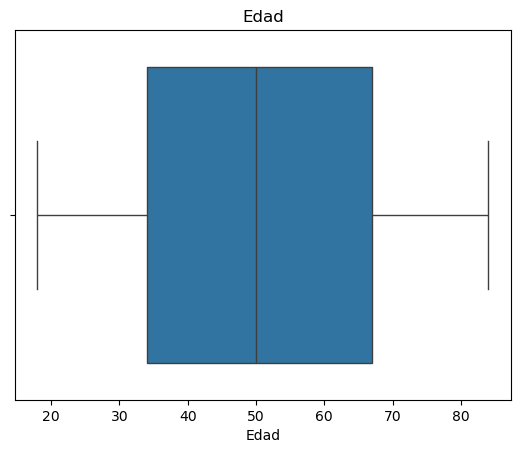

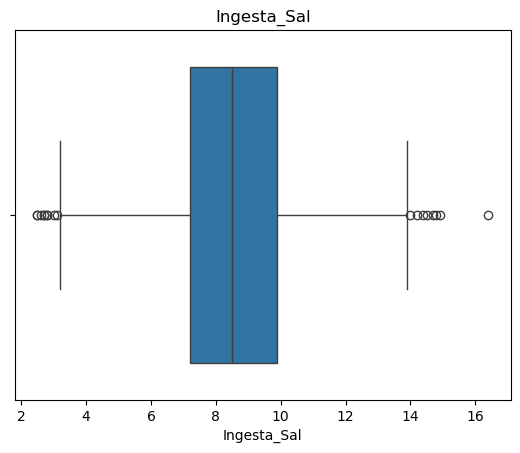

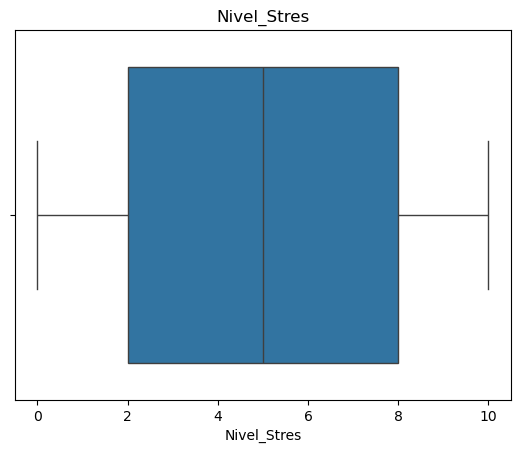

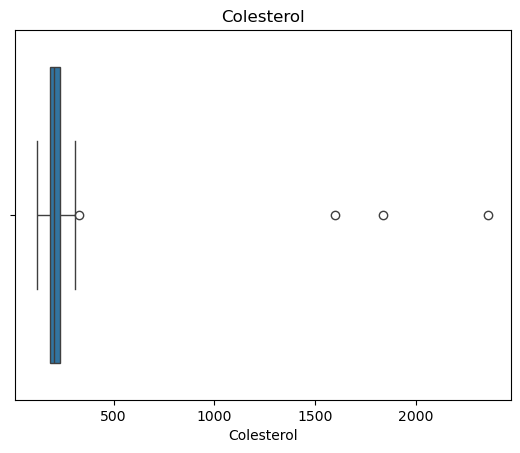

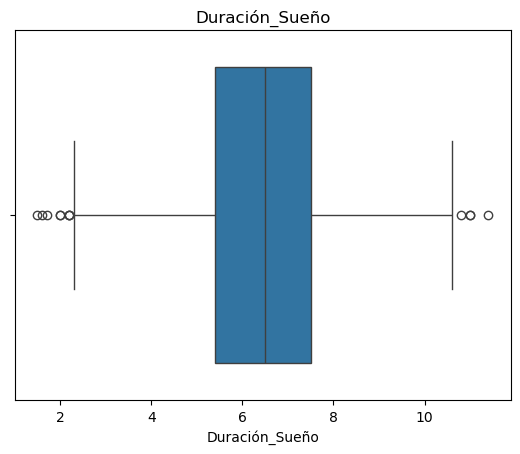

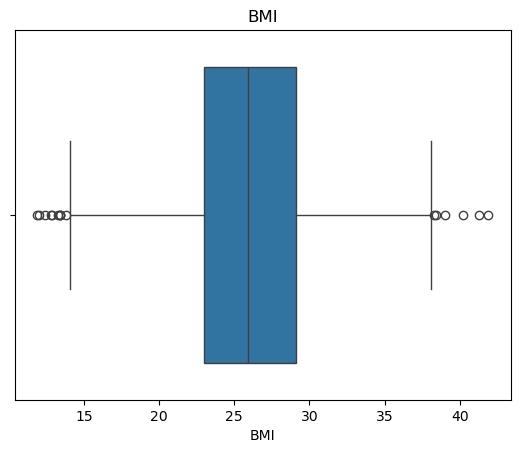

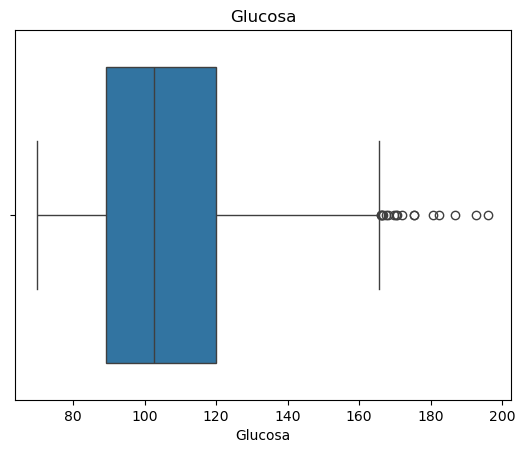

In [6]:
#Grafiquemos la caja ocn bigotes
for col in num_vars.columns:
    plt.figure()
    sns.boxplot(x=data[col])
    plt.title(col)
    plt.show()

In [7]:
# Valores plausibles para cada variable en datos clinicos: Edad(18-90), dataset(18-84)
# Ingesta de sal rango rasonable g/dia (2-20), dataset (2.5-16)
# Nivel de estres (0-10) en el dataset (0-10)
# Duracion del sueño (2-12), en el data set (1.5-11.4)
# BMI indice de grasa corporal (12-60), en el dataset (11.9-41.9)
# colesterol(100-400), dataset (121-326)
# glucosa azucar en sangre (60-300) dataset (70-196)
#Hay cuatro valores de colesterol excesivamente altos, son anomalos, ya que el rango normal suele estar por debo de los 200md/dL
# en casos muy especificos con maximos de 300.
# Vemos tambien un valor muy alto en la ingesta de sal de 16, sin embargo aunque el valor es alto, es biologicamente posible
# Tambien en duracion de sueño hay un valor de 1.5 que es extremo sin embargo, hay casos de insomnio 
# severo que es raro pero posible clinicamente, por lo que es aceptable
Q1 = data["Colesterol"].quantile(0.25)
Q3 = data["Colesterol"].quantile(0.75)
IQR = Q3 - Q1
upper = Q3 + 1.5 * IQR
data[data["Colesterol"] > upper]

,Edad,Ingesta_Sal,Nivel_Stres,Colesterol,Duración_Sueño,BMI,Medicación,Historia_Familiar,Actividad_Fisica,Fumador,Glucosa,Enfermedad_Corazon,Hipertension
12,81,11.0,9,2360.0,8.4,17.3,Ninguna,Si,Baja,No,93.0,No,Si
16,75,9.0,4,1597.0,6.1,25.2,Ninguna,No,Alta,No,92.8,No,No
196,19,9.5,6,1835.0,5.3,33.5,Otro,Si,Alta,No,95.1,No,No
211,53,9.4,4,326.3,6.7,22.1,Otro,No,Moderada,No,119.7,No,Si


In [8]:
data = data[data["Colesterol"] < 400]
Q1 = data["Colesterol"].quantile(0.25)
Q3 = data["Colesterol"].quantile(0.75)
IQR = Q3 - Q1
upper = Q3 + 1.5 * IQR
data[data["Colesterol"] > upper]
#Se detectaron valores extremos en la variable colesterol >1500 mg/dL, considerados fisiológicamente imposibles, 
# por lo que fueron eliminados. Valores altos pero plausibles >300 mg/dL se mantuvieron para preservar la variabilidad clínica del dataset.

,Edad,Ingesta_Sal,Nivel_Stres,Colesterol,Duración_Sueño,BMI,Medicación,Historia_Familiar,Actividad_Fisica,Fumador,Glucosa,Enfermedad_Corazon,Hipertension
211,53,9.4,4,326.3,6.7,22.1,Otro,No,Moderada,No,119.7,No,Si


In [10]:
#Ahora con las categoricas
cat_vars = data.select_dtypes(include=['object', 'category'])
for col in cat_vars.columns:
    print(col)
    print(data[col].value_counts())
    print()
# Podemos observar que, no hay errores de escritura, categorías inesperadas, clases extremadamente raras y esta bien balanceado

Medicación
Medicación
Ninguna           798
BloqueadorBeta    412
InhibidorACE      323
Diuretico         245
Otro              205
Name: count, dtype: int64

Historia_Familiar
Historia_Familiar
No    1000
Si     983
Name: count, dtype: int64

Actividad_Fisica
Actividad_Fisica
Baja        935
Moderada    658
Alta        390
Name: count, dtype: int64

Fumador
Fumador
No    1415
Si     568
Name: count, dtype: int64

Enfermedad_Corazon
Enfermedad_Corazon
No    1508
Si     475
Name: count, dtype: int64

Hipertension
Hipertension
Si    1031
No     952
Name: count, dtype: int64



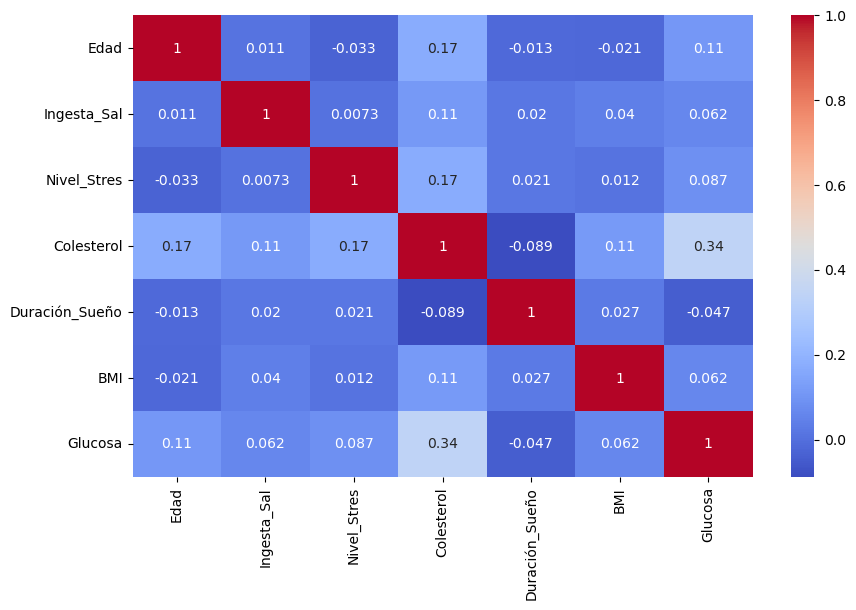

In [11]:
#Bueno, veamos la correlacion entre las variable por medio de una matriz de correlacion, solo para las variables numericas, para ver si se pueden 
#crear nuevas variables o eliminar redundantes
corr = data.corr(numeric_only=True)

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.show()

In [12]:
#Parece que ninugna de las variables es redundante y por lo que no se presenta multicolinealidad fuerte, 
# Ya que su relacion es menor a 0.8 y mayor a -0.8

#Ahora vamos con las categoricas
cat_vars = data.select_dtypes(include=['object','category','bool'])
cat_vars.columns



Index(['Medicación', 'Historia_Familiar', 'Actividad_Fisica', 'Fumador',
       'Enfermedad_Corazon', 'Hipertension'],
      dtype='object')

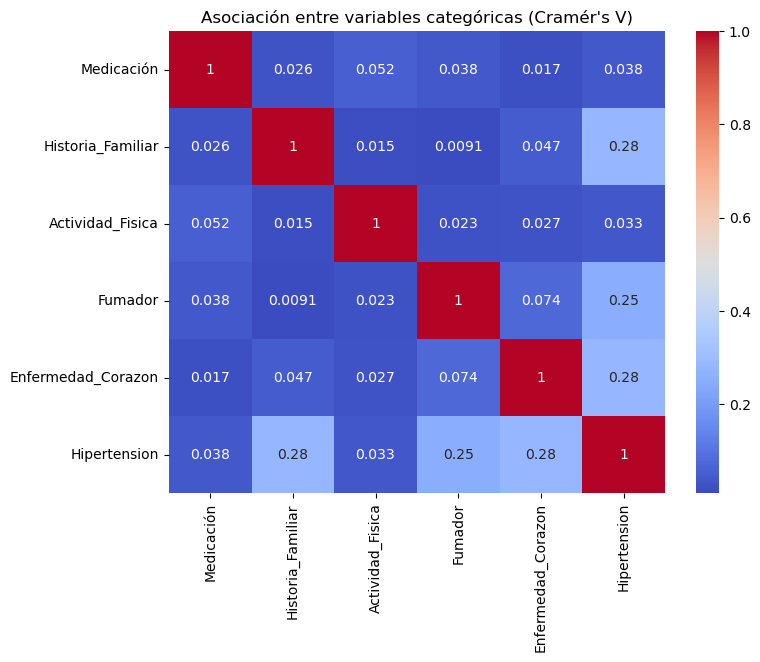

In [13]:
#
def cramers_v(x, y):
    contingency_table = pd.crosstab(x, y)
    chi2 = chi2_contingency(contingency_table)[0]
    n = contingency_table.sum().sum()
    r, k = contingency_table.shape
    return np.sqrt(chi2 / (n * (min(r-1, k-1))))

cat_corr = pd.DataFrame(index=cat_vars.columns, columns=cat_vars.columns)

for col1 in cat_vars.columns:
    for col2 in cat_vars.columns:
        cat_corr.loc[col1, col2] = cramers_v(cat_vars[col1], cat_vars[col2])

cat_corr = cat_corr.astype(float)
cat_corr

plt.figure(figsize=(8,6))
sns.heatmap(cat_corr, annot=True, cmap="coolwarm")
plt.title("Asociación entre variables categóricas (Cramér's V)")
plt.show()

In [14]:
# Separacion de los conjuntos entrenamiento test
x = data.drop("Hipertension", axis=1)
y = data["Hipertension"]
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=77)

In [15]:
#Verificamos que haya quedado bien el split
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(1586, 12)
(397, 12)
(1586,)
(397,)


In [16]:
# volvamos las variables categoricas a numericas tambien
num_cols = x_train.select_dtypes(include=['int64','float64']).columns
cat_cols = x_train.select_dtypes(include=['object']).columns
preprocessor = ColumnTransformer(transformers=[('num', StandardScaler(), num_cols),('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)])
x_train_transformed = preprocessor.fit_transform(x_train)
x_transformed_df = pd.DataFrame(x_train_transformed,columns=preprocessor.get_feature_names_out())
print(x_transformed_df.head())

   num__Edad  num__Ingesta_Sal  num__Nivel_Stres  num__Colesterol  \
0  -1.615102         -0.629398          1.284033        -1.367220   
1  -0.687545         -0.680164          1.284033         0.034212   
2  -1.202854          0.132102          0.647734        -0.231577   
3   0.033888         -0.578631          1.602183         0.940310   
4   0.394605         -1.543197          0.329584         0.136903   

   num__Duración_Sueño  num__BMI  num__Glucosa  \
0             2.291149  0.413891     -0.443529   
1            -0.747060  1.989986     -0.713994   
2             0.222581 -0.134315      0.367868   
3            -1.458130  0.322524      1.400958   
4            -1.458130  0.139788     -1.330301   

   cat__Medicación_BloqueadorBeta  cat__Medicación_Diuretico  \
0                             0.0                        0.0   
1                             0.0                        0.0   
2                             0.0                        0.0   
3                           

In [17]:
# Creamos el pipeline para ambos modelos
recall_scorer = make_scorer(recall_score, pos_label="Si")


#Arboles de decision
tree_model = Pipeline(steps=[("preprocessor", preprocessor),("classifier", DecisionTreeClassifier(random_state=77))])
# hiperparametros
tree_param_grid = {
    "classifier__criterion": ["gini", "entropy"],
    "classifier__max_depth": [4, 6, 8, 10, 12],
    "classifier__min_samples_split": [3, 4, 5]}
# con validacion cruzada de 5 partes, que es lo mas comun 
tree_grid = GridSearchCV(
    tree_model,
    param_grid=tree_param_grid,
    cv=5,
    scoring=recall_scorer)
#Entrenamiento del modelo
tree_grid.fit(x_train, y_train)



,estimator,Pipeline(step...m_state=77))])
,param_grid,"{'classifier__criterion': ['gini', 'entropy'], 'classifier__max_depth': [4, 6, ...], 'classifier__min_samples_split': [3, 4, ...]}"
,scoring,make_scorer(r... pos_label=Si)
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [18]:
#K vecinos
knn_model = Pipeline(steps=[("preprocessor", preprocessor),
                            ("classifier", KNeighborsClassifier())])
knn_param_grid = {
    "classifier__n_neighbors": [1, 2, 3, 4, 5]}
# Grid para KNN
# Aqui pondre en scoring preferiblemente recall, ya que en este caso maximizar la 
# Identificacion de pacientes con hipertension puede evitar victimas fatales
knn_grid = GridSearchCV(
    knn_model,
    param_grid=knn_param_grid,
    cv=5,
    scoring=recall_scorer)
#Entrenamiento del modelo
knn_grid.fit(x_train, y_train)

,estimator,Pipeline(step...lassifier())])
,param_grid,"{'classifier__n_neighbors': [1, 2, ...]}"
,scoring,make_scorer(r... pos_label=Si)
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [19]:
#Observacion de los mejores hiperparametros de ambos modelos
print(tree_grid.best_params_)
y_pred_tree = tree_grid.predict(x_test)
print(knn_grid.best_params_)
y_pred_knn = knn_grid.predict(x_test)

{'classifier__criterion': 'entropy', 'classifier__max_depth': 4, 'classifier__min_samples_split': 3}
{'classifier__n_neighbors': 5}


In [20]:
# Rendimiento de metricas, observemos, accurancy recall F1 score y precision. En relacion 
# a la hipertension como varaible resultante
acc_tree = accuracy_score(y_test, y_pred_tree)
prec_tree = precision_score(y_test, y_pred_tree, pos_label="Si")
rec_tree = recall_score(y_test, y_pred_tree, pos_label="Si")
f1_tree = f1_score(y_test, y_pred_tree, pos_label="Si")

acc_knn = accuracy_score(y_test, y_pred_knn)
prec_knn = precision_score(y_test, y_pred_knn, pos_label="Si")
rec_knn = recall_score(y_test, y_pred_knn, pos_label="Si")
f1_knn = f1_score(y_test, y_pred_knn, pos_label="Si")

#Tabal comaparativa
results = pd.DataFrame({
    "Modelo": ["Decision Tree", "KNN"],
    "Accuracy": [acc_tree, acc_knn],
    "Precision": [prec_tree, prec_knn],
    "Recall": [rec_tree, rec_knn],
    "F1-score": [f1_tree, f1_knn]})
results


,Modelo,Accuracy,Precision,Recall,F1-score
0,Decision Tree,0.901763,0.906977,0.911215,0.909091
1,KNN,0.886650,0.951872,0.831776,0.887781


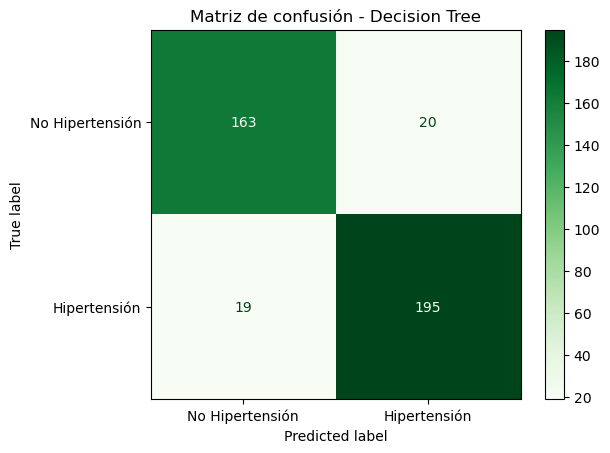

In [22]:
# Ambos modelos tienen precision muy alta 95%, lo cual sugiere que el dataset tiene
#patrones bastante claros para identificar hipertensión.
#El modelo de arboles de decision muestra el mejor desempeño global al presentar mayores 
#valores de accuracy, recall y f1score. Aunque el modelo KNN obtiene una precision
#ligeramente superior, el arbol de decisión logra detectar una mayor proporcion de
# pacientes con hipertension, lo cual es especialmente relevante en problemas medicos.
# Se puede observar quel modelo de k vecinos tiende a ser 
cm_tree = confusion_matrix(y_test, y_pred_tree)
cm_knn = confusion_matrix(y_test, y_pred_knn)
ConfusionMatrixDisplay(
    confusion_matrix=cm_tree,
    display_labels=["No Hipertensión", "Hipertensión"]
).plot(cmap="Greens")

plt.title("Matriz de confusión - Decision Tree")
plt.show()

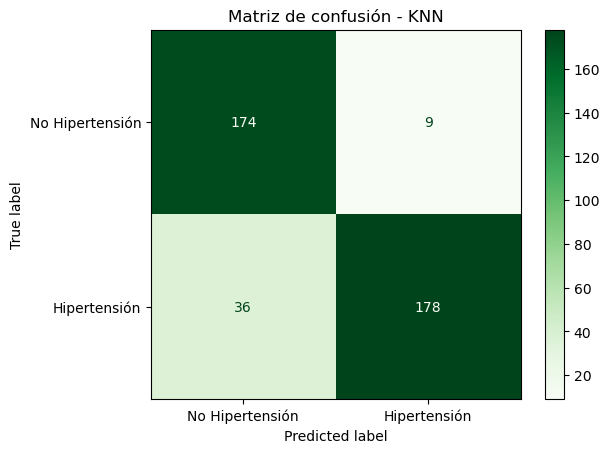

In [23]:
ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=["No Hipertensión", "Hipertensión"]
).plot(cmap="Greens")

plt.title("Matriz de confusión - KNN")
plt.show()

In [24]:
# El recall del árbol es 0.91, lo que significa que detecta aproximadamente el 91% 
# de los pacientes hipertensos, lo cual es bastante bueno para este tipo de modelo.


#Intervalo de confianza Bootstrapping 
# Busca estimar que tan estable es el rendimiento del modelo
# La tecnica consiste en 
#1 Tomar muchas muestras aleatorias con reemplazo del dataset
#2 Calcular una métrica (por ejemplo accuracy) en cada muestra
#3 Usar la distribucion de  valores para estimar un intervalo de confianza

# Si se usa recall el intervalo de confianza del modelo detecta entre X% y Y% 
#de los pacientes hipertensos.

#Por lo tanto
#Dado que el objetivo principal del modelo es identificar pacientes con hipertensión,
#se utilizó la métrica de recall para evaluar su desempeño mediante bootstrapping.
#Esta métrica permite estimar la proporción de casos positivos correctamente
#identificados por el modelo. El intervalo de confianza obtenido indica la estabilidad 
#del modelo en la detección de pacientes hipertensos.

n_iterations = 1000
scores = []

n_size = len(x_test)

for i in range(n_iterations):
    
    # muestra bootstrap
    indices = np.random.choice(range(n_size), n_size, replace=True)
    
    x_sample = x_test.iloc[indices]
    y_sample = y_test.iloc[indices]
    
    # predicción con el mejor modelo (Decision Tree)
    y_pred = tree_grid.predict(x_sample)
    
    # calcular recall
    score = recall_score(y_sample, y_pred, pos_label="Si")
    
    scores.append(score)

scores = np.array(scores)

# intervalo de confianza 95%
lower = np.percentile(scores, 2.5)
upper = np.percentile(scores, 97.5)

print("Intervalo de confianza (95%) para Recall:")
print(lower, upper)

Intervalo de confianza (95%) para Recall:
0.8726316390989942 0.9452071832617733


In [25]:
#Con un nivel de confianza del 95%, el recall del modelo de árboles de decisión
# se encuentra aproximadamente entre 0.87 y 0.95.Esto indica que el modelo es
#capaz de identificar correctamente entre 87% y 95% de los pacientes con hipertensión 
#en nuevos datos. Numero de iteracionees: 1000
# Se escogio un intervalod e confianza del 95 ya que si hubiera elegido intervalo de 
# confianza del 99%, el intervalo sería más ancho, porque necesitaria capturar mas 
#incertidumbre.


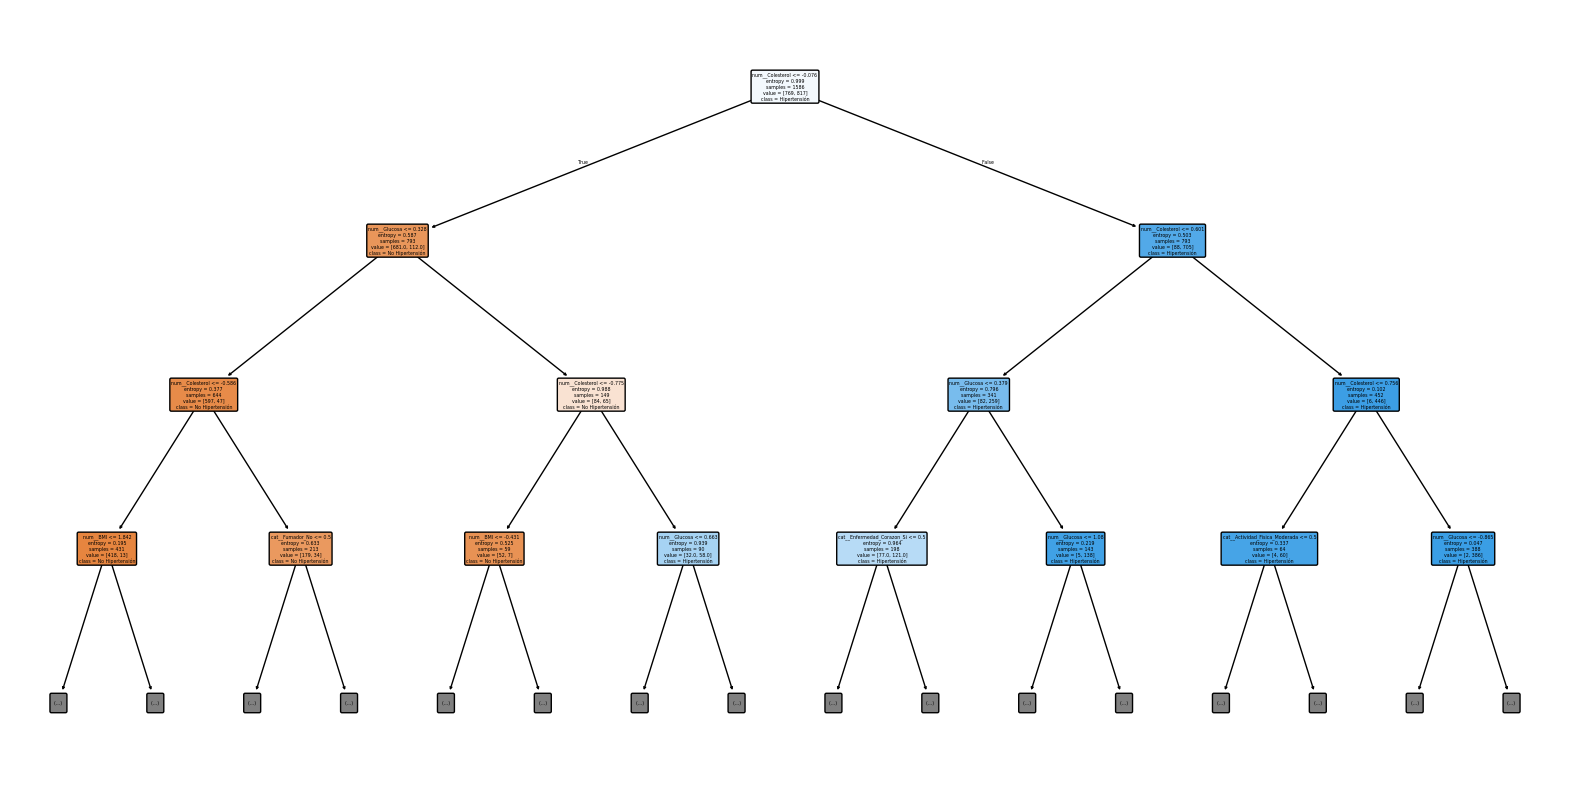

In [26]:
# Obtener las reglas del arbol de decision con profundidad maxima 3
tree = tree_grid.best_estimator_.named_steps["classifier"]
#Obtener el nombre de las varaibles
feature_names = preprocessor.get_feature_names_out()
plt.figure(figsize=(20,10))
plot_tree(
    tree,
    feature_names=feature_names,
    class_names=["No Hipertensión","Hipertensión"],
    filled=True,
    rounded=True,
    max_depth=3)
plt.show()

In [27]:
rules = export_text(tree, feature_names=list(feature_names), max_depth=3)
print(rules)

|--- num__Colesterol <= -0.08
|   |--- num__Glucosa <= 0.33
|   |   |--- num__Colesterol <= -0.59
|   |   |   |--- num__BMI <= 1.84
|   |   |   |   |--- class: No
|   |   |   |--- num__BMI >  1.84
|   |   |   |   |--- class: No
|   |   |--- num__Colesterol >  -0.59
|   |   |   |--- cat__Fumador_No <= 0.50
|   |   |   |   |--- class: No
|   |   |   |--- cat__Fumador_No >  0.50
|   |   |   |   |--- class: No
|   |--- num__Glucosa >  0.33
|   |   |--- num__Colesterol <= -0.78
|   |   |   |--- num__BMI <= -0.43
|   |   |   |   |--- class: No
|   |   |   |--- num__BMI >  -0.43
|   |   |   |   |--- class: No
|   |   |--- num__Colesterol >  -0.78
|   |   |   |--- num__Glucosa <= 0.66
|   |   |   |   |--- class: No
|   |   |   |--- num__Glucosa >  0.66
|   |   |   |   |--- class: Si
|--- num__Colesterol >  -0.08
|   |--- num__Colesterol <= 0.60
|   |   |--- num__Glucosa <= 0.38
|   |   |   |--- cat__Enfermedad_Corazon_Si <= 0.50
|   |   |   |   |--- class: Si
|   |   |   |--- cat__Enfermedad_C

In [28]:
#Las reglas obtenidas del árbol de decisión muestran que variables como el colesterol, 
#los niveles de glucosa, el índice de masa corporal (BMI) y algunos factores de estilo 
# de vida influyen en la predicción de hipertensión.En particular, el árbol utiliza el 
# colesterol como una de las primeras variables para dividir a los pacientes. 
#Cuando los niveles de colesterol son relativamente bajos, el modelo tiende a clasificar 
# a los pacientes como no hipertensos, especialmente cuando la glucosa también se 
#encuentra en valores bajos o moderados. Por el contrario, cuando el colesterol se 
# encuentra por encima del promedio, el modelo tiende a clasificar a los pacientes 
#como hipertensos, especialmente si además presentan niveles elevados de glucosa o 
# antecedentes de enfermedad cardiovascular.

#El hecho de que Colesterol aparezca en la raíz del árbol significa que fue la variable
#más informativa para separar los pacientes según el modelo.
# este seria el orden de imporancia a la hora de decidir la clasificaion de hipertension
#como positiva:



In [29]:
#1 Colesterol
#2 Glucosa
#3 Indice de masa corporal
#4 Enfermedad cardíaca
#5 Actividad física / tabaquismo

# Calculo de la importancia de cada variable
# Disminución media de la impureza (%)
# cuánto reduce la impureza cada variable
importances = tree.feature_importances_

importance_df = pd.DataFrame({
    "Variable": feature_names,
    "Importancia": importances
})

importance_df = importance_df.sort_values(by="Importancia", ascending=False)

importance_df["Porcentaje (%)"] = importance_df["Importancia"] * 100

importance_df.head(10)

,Variable,Importancia,Porcentaje (%)
3,num__Colesterol,0.812213,81.221323
6,num__Glucosa,0.137050,13.704951
5,num__BMI,0.015484,1.548407
20,cat__Enfermedad_Corazon_Si,0.015207,1.520725
17,cat__Fumador_No,0.013897,1.389654
16,cat__Actividad_Fisica_Moderada,0.006149,0.614940
12,cat__Historia_Familiar_No,0.000000,0.000000
19,cat__Enfermedad_Corazon_No,0.000000,0.000000
18,cat__Fumador_Si,0.000000,0.000000
15,cat__Actividad_Fisica_Baja,0.000000,0.000000


In [ ]:
# Analisis de resultados
# ¿Qué puedes decir de los valores de las métricas recall y precisión para 
# cada una de las clases en cada modelo? ¿Cuál de estás métricas consideras 
# que es más importante con base en la descripción del problema?


# Métricas recall y precisión por clase
#Los modelos evaluados (árbol de decisión y K-vecinos más cercanos) 
#presentan valores relativamente altos tanto en precisión como en recall, 
#lo que indica un buen desempeño general en la clasificación de pacientes 
# con hipertensión.
#La precisión (precision) mide qué proporción de los pacientes que el modelo
# clasifica como hipertensos realmente lo son. Un valor alto indica que el 
# modelo comete pocos falsos positivos.
#El recall (sensibilidad) mide qué proporción de los pacientes que realmente tienen 
#hipertensión fueron correctamente identificados por el modelo. Un valor alto indica que el modelo comete pocos falsos negativos.
# En este problema clínico, el recall es la métrica más importante, 
# ya que un falso negativo implica no detectar a un paciente con
# hipertensión, lo cual podría retrasar su tratamiento y aumentar el 
# riesgo de complicaciones cardiovasculares.
# Por esta razón, durante el ajuste del modelo se priorizó maximizar 
# el recall en el proceso de validación cruzada.


#¿Consideras que el rendimiento de los modelos es adecuado? Si no es así, 
# ¿Cómo podrían mejorarse los resultados?

#¿El rendimiento de los modelos es adecuado?
# Los modelos presentan un rendimiento adecuado. 
# El árbol de decisión alcanzó aproximadamente:
# Accuracy ≈ 0.90
# Recall ≈ 0.91
# Precision ≈ 0.91
# F1-score ≈ 0.91
# Estos valores indican que el modelo logra identificar correctamente una 
# alta proporción de pacientes con hipertensión y mantiene un buen equilibrio 
# entre precisión y sensibilidad.
# Sin embargo, los resultados podrían mejorarse mediante:
# utilizar más datos de entrenamiento
# aplicar técnicas de balanceo de clases (SMOTE, class weights)
# explorar modelos más complejos como Random Forest o Gradient Boosting
# realizar una optimización más amplia de hiperparámetros
# incluir más variables clínicas relevantes
# Estas mejoras podrían aumentar la capacidad del modelo para generalizar 
# a nuevos pacientes.




#¿Cuáles son las variables más significativas según el mejor modelo basado 
# en árboles de decisión? Reflexiona sobre cómo este nuevo conocimiento 
# podría ayudar a tomar decisiones en el contexto del problema.


#Variables más significativas según el árbol de decisión
#El análisis de importancia de variables mostró que las más influyentes en
#la predicción de hipertensión fueron:

# Colesterol
# Glucosa
# Índice de masa corporal (BMI)
# Presencia de enfermedad cardíaca
# Nivel de actividad física y tabaquismo

# Esto tiene sentido desde el punto de vista clínico, ya que estos factores
#están ampliamente asociados con enfermedades cardiovasculares y con el 
#desarrollo de hipertensión.
# Este conocimiento puede ayudar a:
# identificar pacientes con mayor riesgo
# priorizar programas de prevención
# orientar intervenciones médicas y cambios en el estilo de vida
# Por ejemplo, pacientes con colesterol alto, glucosa elevada y 
#mayor BMI podrían ser monitoreados con mayor frecuencia.



#Si ambos modelos presentan resultados similares en las métricas de desempeño,
#¿Cuál seleccionarías considerando el contexto clínico del problema? 
# Justifica tu elección.

# Si ambos modelos tienen resultados similares, ¿cuál elegir?
# Aunque ambos modelos presentan métricas de desempeño similares, el modelo
#de árbol de decisión sería preferible en un contexto clínico. por esta razon 
# Se uso como metrica el recall para evitar los FNs
# tambien se debe a que los árboles de decisión son más interpretables 
# que modelos como KNN. El árbol permite generar reglas claras de decisión, 
# por ejemplo:
#si colesterol alto
# y glucosa elevada
# entonces mayor riesgo de hipertensión
# Esta interpretabilidad es muy importante en medicina, ya que los profesionales 
# de salud necesitan entender cómo el modelo toma decisiones para confiar en 
# sus predicciones.
#Por lo tanto, el árbol de decisión ofrece una ventaja importante al combinar
# buen rendimiento con interpretabilidad clínica.




#¿Qué indica el intervalo de confianza estimado sobre la estabilidad y confiabilidad
# del modelo seleccionado?
# Interpretación del intervalo de confianza (bootstrapping)
# Mediante la técnica de bootstrapping se estimó un intervalo de confianza
# del 95% para el recall del modelo de árbol de decisión.
# El intervalo obtenido fue aproximadamente:
# 0.87 – 0.95
# Esto indica que, con un 95% de confianza, el verdadero valor del recall
#del modelo se encuentra dentro de ese rango.
#Este resultado sugiere que el modelo es relativamente estable y confiable, 
# ya que incluso en el peor escenario dentro del intervalo sigue manteniendo 
#un nivel alto de detección de pacientes con hipertensión.
# En términos prácticos, esto significa que el modelo tiene una alta 
# probabilidad de identificar correctamente a la mayoría de los pacientes 
#hipertensos, lo cual es fundamental para su aplicación en un contexto clínico.

